# Lezione 13 — Caso Aula
## Silicon Valley Bank 2023 — piano ALM, sensitività e scenari di stress

### Prompt 1 — Inquadramento del caso

La **Scheda Caso Aula** costituisce la specifica vincolante del lavoro e non deve essere modificata.

**Domanda quantitativa.** Come cambia il piano ALM ottimo di SVB al variare separatamente e congiuntamente del fabbisogno di liquidità, della capacità massima di funding e del costo del funding, e fino a quale livello di aumento dei fabbisogni iniziali il problema resta ammissibile?

**Driver**
- $\theta$: fabbisogni delle prime due date;
- $\phi$: capacità massima di funding;
- $\psi$: costo del funding e relativo rimborso.

**Quantità da determinare**
- benchmark: $x^*$, $g^*$, $u^*$, $\Pi^*$;
- residuali, slack, bounds attivi e principali marginali;
- sensitività univariate a $\theta$, $\phi$, $\psi$;
- variazioni rispetto al benchmark e utilizzo della capacità di funding;
- ultimo $\theta$ ammissibile, primo non ammissibile e intervallo raffinato contenente $\theta_{\mathrm{crit}}$;
- soluzioni e perdite di valore nei tre scenari assegnati.

**Tabelle richieste**
1. Parametri benchmark.
2. Soluzione benchmark.
3. Verifica dei bilanci temporali.
4. Vincoli, bounds e slack benchmark.
5. Valori marginali benchmark.
6. Sensitività a $\theta$.
7. Sensitività a $\phi$.
8. Sensitività a $\psi$.
9. Raffinamento della frontiera di fattibilità.
10. Confronto degli scenari.

**Figure richieste**
1. Valore ottimo rispetto a $\theta$.
2. Variazione del valore ottimo rispetto a $\theta$.
3. Composizione dell'attivo rispetto a $\theta$.
4. Variazioni dell'asset allocation.
5. Funding e utilizzo della capacità rispetto a $\theta$.
6. Giacenze rispetto a $\theta$.
7. Sensitività a $\phi$.
8. Sensitività a $\psi$.
9. Valori marginali.
10. Mappa dei principali vincoli attivi.
11. Valore ottimo nei tre scenari.
12. Composizione dell'attivo nei tre scenari.
13. Funding nei tre scenari.
14. Giacenze nei tre scenari.

**Controlli**
- residuali, slack, bounds, prudenziale, $x_3\leq30$, funding e non negatività;
- variazione di un solo parametro alla volta;
- distinzione tra sensitività, frontiera e scenari;
- corretta azione di $\psi$ sia nell'obiettivo sia nei rimborsi;
- verifica perturbativa di almeno un marginale;
- esclusione dall'analisi delle configurazioni non ammissibili;
- riproducibilità integrale.

## Prompt 2 — Flusso logico-teorico risolutivo
**Regime A**

| Passo | Finalità risolutiva | Formula / proprietà | Applicazione nel caso | Output o controllo |
|---:|---|---|---|---|
| 1 | Ricostruire il modello e tradurlo nella forma solver | PL; uguaglianze; disuguaglianze; bounds; $\max\Pi\leftrightarrow\min(-\Pi)$ | Ordinamento, obiettivo, matrici, bounds | Struttura solver e controlli dimensionali |
| 2 | Risolvere e validare il benchmark | Ammissibilità, residuali, slack, bounds attivi, dualità locale | $(1,1,1)$ e verifica di almeno un marginale | $x^*,g^*,u^*,\Pi^*$ e diagnostica |
| 3 | Costruire il solver parametrico | Analisi parametrica | Introdurre $\theta,\phi,\psi$ solo dove previsto | `solve(theta,phi,psi)` e replica benchmark |
| 4 | Analizzare $\theta$ e la frontiera | Comparative statics; feasible/infeasible | Griglia $\theta$ e raffinamento | Tabelle, figure, intervallo di $\theta_{\mathrm{crit}}$ |
| 5 | Analizzare la capacità di funding | Bounds parametrizzati | Sensitività a $\phi$ | Tabella 7 e Figura 7 |
| 6 | Analizzare il costo del funding | Coefficienti economici e rimborso | Sensitività a $\psi$ con doppia applicazione | Tabella 8 e Figura 8 |
| 7 | Confrontare sensitività e scenari | Comparative statics; scenario analysis | Confronto dei driver e tre scenari | Sintesi, Tabella 10, Figure 11–14 |
| 8 | Verificare coerenza e limiti | Coerenza modello–solver–output | Checklist finale e limiti interpretativi | Base quantitativa per il commento finale |

## Prompt 3 — Scomposizione in tappe input-output
**Regime A/B**

| Tappa | Titolo | Obiettivo | Input | Operazione | Output | Controllo | Uso successivo | Regime |
|---:|---|---|---|---|---|---|---|:---:|
| 1 | Forma solver | Tradurre il modello | Scheda Caso e parametri | Costruire vettori, matrici e bounds | Struttura solver + Tabella 1 | Dimensioni, coefficienti, segni | Benchmark | A/B |
| 2 | Benchmark, diagnostica e marginali | Risolvere e validare | Forma solver | `linprog`, diagnostica, perturbazione | Tabelle 2–5 | Fattibilità e marginale locale | Parametrizzazione | B |
| 3 | Solver parametrico, $\theta$ e frontiera | Generalizzare e stressare i fabbisogni | Benchmark validato | `solve`, griglia $\theta$, raffinamento | Tabelle 6 e 9; Figure 1–6, 9–10 | Unico driver, feasible/infeasible | Altri driver | A/B |
| 4 | $\phi$ e $\psi$ | Analizzare capacità e costo | Solver parametrico | Due griglie separate | Tabelle 7–8; Figure 7–8 | $\phi$ solo bounds; $\psi$ obiettivo+rimborsi | Confronto | B |
| 5 | Confronto e scenari | Mettere in relazione i driver | Risultati precedenti | Sintesi e tre scenari | Tabella 10; Figure 11–14 | Standard=benchmark; parametri esatti | Chiusura | A/B |
| 6 | Controlli conclusivi | Validare il notebook | Tutti gli output | Checklist e limiti | Sintesi quantitativa | Completezza e riproducibilità | Interpretazione finale | A |

# Tappa 1 — Traduzione del modello nella forma solver
**Regime A/B**

**Obiettivo.** Costruire una rappresentazione fedele alla Scheda Caso.

**Input.** Parametri benchmark, matrice dei cash flow e formule vincolanti.

**Oggetti teorici.**
- vettore decisionale $z=(x_1,\ldots,x_4,g_1,\ldots,g_4,u_1,u_2,u_3)'$;
- funzione economica $\max\Pi$ e convenzione solver $\min F=-\Pi$;
- cinque uguaglianze: risorse iniziali + quattro bilanci;
- due disuguaglianze: prudenziale e limite $x_3\leq30$;
- bounds di non negatività e funding.

**Output.** Tabella 1, vettore obiettivo, matrici, termini noti e bounds.

**Controllo.** Dimensioni, ordinamento, coefficienti e segni.

**Uso successivo.** La struttura validata alimenta la soluzione benchmark.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
TOL = 1e-8

A0 = 100.0
c = np.array([0.010, 0.025, 0.040, 0.050])
ell = np.array([0.000, 0.020, 0.150, 0.080])
A_CF = np.array([
    [1.00, 0.65, 0.05, 0.05],
    [0.00, 0.35, 0.10, 0.15],
    [0.00, 0.00, 0.25, 0.30],
    [0.00, 0.00, 0.60, 0.50],
])
d0 = np.array([30.0, 30.0, 22.0, 15.0])
r_g = np.array([0.005, 0.006, 0.007])
r_u = np.array([0.015, 0.020, 0.025])
u_bar = np.array([10.0, 8.0, 6.0])
K = 7.0
x3_max = 30.0

names = [f"x{i}" for i in range(1,5)] + [f"g{i}" for i in range(1,5)] + [f"u{i}" for i in range(1,4)]
idx = {n:i for i,n in enumerate(names)}
n = len(names)

tab1 = pd.DataFrame({
    "Quantità": ["A0","c","ell","d","r_g","r_u","u_bar","K","x3_max"],
    "Valore": [A0,c.tolist(),ell.tolist(),d0.tolist(),r_g.tolist(),r_u.tolist(),u_bar.tolist(),K,x3_max]
})
print("Tabella 1 — Parametri benchmark")
display(tab1)
print("Matrice A_CF")
display(pd.DataFrame(A_CF, index=["t1","t2","t3","t4"], columns=["x1","x2","x3","x4"]))

def build_aula(theta=1.0, phi=1.0, psi=1.0, d_override=None):
    d = np.array([30*theta, 30*theta, 22.0, 15.0]) if d_override is None else np.asarray(d_override, float)
    f = np.zeros(n)
    f[:4] = -c
    f[idx["g1"]:idx["g4"]] = -r_g
    f[idx["u1"]:idx["u3"]+1] = psi*r_u

    Aeq, beq = [], []
    row = np.zeros(n); row[:4] = 1; Aeq.append(row); beq.append(A0)
    row = np.zeros(n); row[:4]=A_CF[0]; row[idx["u1"]]=1; row[idx["g1"]]=-1; Aeq.append(row); beq.append(d[0])
    row = np.zeros(n); row[:4]=A_CF[1]; row[idx["g1"]]=1+r_g[0]; row[idx["u1"]]=-(1+psi*r_u[0]); row[idx["u2"]]=1; row[idx["g2"]]=-1; Aeq.append(row); beq.append(d[1])
    row = np.zeros(n); row[:4]=A_CF[2]; row[idx["g2"]]=1+r_g[1]; row[idx["u2"]]=-(1+psi*r_u[1]); row[idx["u3"]]=1; row[idx["g3"]]=-1; Aeq.append(row); beq.append(d[2])
    row = np.zeros(n); row[:4]=A_CF[3]; row[idx["g3"]]=1+r_g[2]; row[idx["u3"]]=-(1+psi*r_u[2]); row[idx["g4"]]=-1; Aeq.append(row); beq.append(d[3])

    Aub, bub = [], []
    row=np.zeros(n); row[:4]=ell; Aub.append(row); bub.append(K)
    row=np.zeros(n); row[idx["x3"]]=1; Aub.append(row); bub.append(x3_max)

    bounds=[(0,None)]*8 + [(0,phi*u_bar[t]) for t in range(3)]
    return f,np.array(Aeq),np.array(beq),np.array(Aub),np.array(bub),bounds,d

f,A_eq,b_eq,A_ub,b_ub,bounds,_ = build_aula()
assert f.shape==(11,)
assert A_eq.shape==(5,11)
assert A_ub.shape==(2,11)
assert len(bounds)==11
assert np.isclose(A_ub[1,idx["x3"]],1.0)
print("Controlli forma solver: OK")

Tabella 1 — Parametri benchmark


,Quantità,Valore
0,A0,100.0
1,c,"[0.01, 0.025, 0.04, 0.05]"
2,ell,"[0.0, 0.02, 0.15, 0.08]"
3,d,"[30.0, 30.0, 22.0, 15.0]"
4,r_g,"[0.005, 0.006, 0.007]"
5,r_u,"[0.015, 0.02, 0.025]"
6,u_bar,"[10.0, 8.0, 6.0]"
7,K,7.0
8,x3_max,30.0


Matrice A_CF


,x1,x2,x3,x4
t1,1.0,0.65,0.05,0.05
t2,0.0,0.35,0.10,0.15
t3,0.0,0.00,0.25,0.30
t4,0.0,0.00,0.60,0.50


Controlli forma solver: OK


# Tappa 2 — Benchmark, diagnostica e valori marginali
**Regime B**

**Obiettivo.** Risolvere $(\theta,\phi,\psi)=(1,1,1)$ e validare la soluzione prima di parametrizzare.

**Input.** Forma solver validata.

**Operazioni.**
1. risoluzione con `linprog(method="highs")`;
2. ricostruzione di $\Pi^*=-F^*$;
3. verifica indipendente dei bilanci;
4. slack, bounds attivi e marginali;
5. perturbazione numerica di un termine noto per verificare un marginale locale.

**Output.** Tabelle 2–5.

**Controllo.** Stato solver, residuali, prudenziale, $x_3\leq30$, bounds di funding, non negatività e coerenza del marginale.

**Uso successivo.** Il benchmark validato alimenta il solver parametrico.

In [2]:
res = linprog(f,A_ub=A_ub,b_ub=b_ub,A_eq=A_eq,b_eq=b_eq,bounds=bounds,method="highs")
assert res.success
z = res.x
x,g,u = z[:4],z[4:8],z[8:11]
Pi = -res.fun

print("Tabella 2 — Soluzione benchmark")
tab2 = pd.DataFrame({"Variabile":names,"Valore ottimo":z})
display(tab2)
display(pd.DataFrame({"Quantità":["Pi*"],"Valore":[Pi]}))

print("Tabella 3 — Verifica dei bilanci temporali")
rows=[]
for t in range(4):
    cf=float(A_CF[t]@x)
    carry=0 if t==0 else (1+r_g[t-1])*g[t-1]
    newfund=0 if t==3 else u[t]
    repay=0 if t==0 else (1+r_u[t-1])*u[t-1]
    lhs=cf+carry+newfund-repay-g[t]
    rows.append([t+1,cf,carry,newfund,repay,d0[t],g[t],lhs-d0[t]])
tab3=pd.DataFrame(rows,columns=["data","cash_flow_attivi","giacenza_precedente","funding_corrente","rimborso_funding","fabbisogno","giacenza_finale","residuo"])
display(tab3)

print("Tabella 4 — Vincoli, bounds e slack benchmark")
ub_slack=b_ub-A_ub@z
rows=[
    ["prudenziale",float(ell@x),K,ub_slack[0],abs(ub_slack[0])<=TOL],
    ["x3_max",x[2],x3_max,ub_slack[1],abs(ub_slack[1])<=TOL],
]
for j,(lo,hi) in enumerate(bounds):
    if lo is not None:
        rows.append([f"{names[j]} lower",z[j],lo,z[j]-lo,abs(z[j]-lo)<=TOL])
    if hi is not None:
        rows.append([f"{names[j]} upper",z[j],hi,hi-z[j],abs(hi-z[j])<=TOL])
tab4=pd.DataFrame(rows,columns=["restrizione","valore","limite","slack/distanza","attivo"])
display(tab4)

print("Tabella 5 — Valori marginali benchmark")
mrows=[]
eq_labels=["risorse","bilancio_t1","bilancio_t2","bilancio_t3","bilancio_t4"]
for lab,m in zip(eq_labels,res.eqlin.marginals):
    mrows.append([lab,"uguaglianza",m,-m])
for lab,m in zip(["prudenziale","x3_max"],res.ineqlin.marginals):
    mrows.append([lab,"disuguaglianza",m,-m])
for j,name in enumerate(names):
    if bounds[j][1] is not None:
        mrows.append([f"{name}_upper","bound superiore",res.upper.marginals[j],-res.upper.marginals[j]])
tab5=pd.DataFrame(mrows,columns=["oggetto","tipo","marginale_F","marginale_Pi_rispetto_RHS"])
display(tab5)

# verifica perturbativa sul RHS del bilancio t1
eps=1e-4
b_pert=b_eq.copy(); b_pert[1]+=eps
rp=linprog(f,A_ub=A_ub,b_ub=b_ub,A_eq=A_eq,b_eq=b_pert,bounds=bounds,method="highs")
assert rp.success
num=( -rp.fun - Pi )/eps
theo=-res.eqlin.marginals[1]
display(pd.DataFrame({"controllo":["derivata numerica","-marginale solver","errore assoluto"],"valore":[num,theo,abs(num-theo)]}))

assert np.max(np.abs(A_eq@z-b_eq))<1e-7
assert np.all(ub_slack>=-1e-7)
assert np.min(z)>=-1e-7
assert abs(num-theo)<1e-6
print("Benchmark e verifica marginale: OK")

Tabella 2 — Soluzione benchmark


,Variabile,Valore ottimo
0,x1,0.000000
1,x2,51.919684
2,x3,0.000000
3,x4,48.080316
4,g1,6.151810
5,g2,1.566506
6,g3,0.000000
7,g4,2.890158
8,u1,0.000000
9,u2,0.000000


,Quantità,Valore
0,Pi*,3.592166


Tabella 3 — Verifica dei bilanci temporali


,data,cash_flow_attivi,giacenza_precedente,funding_corrente,rimborso_funding,fabbisogno,giacenza_finale,residuo
0,1,36.151810,0.000000,0.0,0.00,30.0,6.151810,-3.552714e-15
1,2,25.383937,6.182569,0.0,0.00,30.0,1.566506,7.105427e-15
2,3,14.424095,1.575905,6.0,0.00,22.0,0.000000,0.000000e+00
3,4,24.040158,0.000000,0.0,6.15,15.0,2.890158,0.000000e+00


...

,restrizione,valore,limite,slack/distanza,attivo
0,prudenziale,4.884819,7.0,2.115181,False
1,x3_max,0.000000,30.0,30.000000,False
2,x1 lower,0.000000,0.0,0.000000,True
3,x2 lower,51.919684,0.0,51.919684,False
4,x3 lower,0.000000,0.0,0.000000,True
5,x4 lower,48.080316,0.0,48.080316,False
6,g1 lower,6.151810,0.0,6.151810,False
7,g2 lower,1.566506,0.0,1.566506,False
8,g3 lower,0.000000,0.0,0.000000,True
9,g4 lower,2.890158,0.0,2.890158,False


Tabella 5 — Valori marginali benchmark


,oggetto,tipo,marginale_F,marginale_Pi_rispetto_RHS
0,risorse,uguaglianza,-0.068418,0.068418
1,bilancio_t1,uguaglianza,0.045238,-0.045238
2,bilancio_t2,uguaglianza,0.040038,-0.040038
3,bilancio_t3,uguaglianza,0.033835,-0.033835
4,bilancio_t4,uguaglianza,-0.000000,0.000000
5,prudenziale,disuguaglianza,-0.000000,0.000000
6,x3_max,disuguaglianza,-0.000000,0.000000
7,u1_upper,bound superiore,0.000000,-0.000000
8,u2_upper,bound superiore,0.000000,-0.000000
9,u3_upper,bound superiore,-0.008835,0.008835


,controllo,valore
0,derivata numerica,-4.523816e-02
1,-marginale solver,-4.523816e-02
2,errore assoluto,4.304071e-12


Benchmark e verifica marginale: OK


# Tappa 3 — Solver parametrico, sensitività a $\theta$ e frontiera di fattibilità
**Regime A/B**

**Obiettivo.** Generalizzare il benchmark e analizzare lo stress sui fabbisogni fino alla perdita di fattibilità.

**Input.** Benchmark validato e definizioni di $\theta$, $\phi$, $\psi$.

**Operazioni.**
- costruire `solve_aula(theta, phi, psi)`;
- verificare la riproduzione del benchmark;
- eseguire la griglia $\theta\in\{1.00,\ldots,1.10\}$ con $\phi=\psi=1$;
- produrre Tabella 6 e Figure 1–6, 9–10;
- individuare ultimo feasible e primo infeasible;
- raffinare soltanto il relativo bracket e produrre Tabella 9.

**Controllo.** $\theta$ modifica soltanto i primi due fabbisogni; configurazioni non ammissibili non vengono interpretate.

**Uso successivo.** La funzione validata alimenta le sensitività a $\phi$, $\psi$ e gli scenari.

Tabella 6 — Sensitività a theta


,theta,success,status,Pi,Delta_Pi,Delta_Pi_pct,x1,Delta_x1,x2,Delta_x2,x3,Delta_x3,x4,Delta_x4,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,prud_slack,x3_slack,u1_upper_slack,u2_upper_slack,u3_upper_slack,marg_t1_Pi,marg_t2_Pi,marg_t3_Pi,marg_t4_Pi
0,1.00,True,0,3.592166,0.000000,0.000000,0.000000,0.000000,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,1.566506,0.00000,2.890158,0.0,0.0,0.0,0.0,6.00000,1.000000,2.115181,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
1,1.01,True,0,3.566583,-0.025583,-0.712184,0.000000,0.000000,53.111270,1.191586,0.0,0.0,46.888730,-1.191586,6.566762,1.921850,0.00000,2.294365,0.0,0.0,0.0,0.0,6.00000,1.000000,2.186676,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
2,1.02,True,0,3.541000,-0.051166,-1.424368,0.000000,0.000000,54.302857,2.383173,0.0,0.0,45.697143,-2.383173,6.981714,2.277194,0.00000,1.698572,0.0,0.0,0.0,0.0,6.00000,1.000000,2.258171,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
3,1.03,True,0,3.515417,-0.076749,-2.136552,0.000000,0.000000,55.494443,3.574759,0.0,0.0,44.505557,-3.574759,7.396666,2.632538,0.00000,1.102779,0.0,0.0,0.0,0.0,6.00000,1.000000,2.329667,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
4,1.04,True,0,3.489835,-0.102331,-2.848737,0.000000,0.000000,56.686029,4.766345,0.0,0.0,43.313971,-4.766345,7.811618,2.987881,0.00000,0.506985,0.0,0.0,0.0,0.0,6.00000,1.000000,2.401162,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
5,1.05,True,0,3.444828,-0.147338,-4.101636,0.000000,0.000000,62.206863,10.287179,0.0,0.0,37.793137,-10.287179,10.824118,6.819611,0.00000,0.000000,0.0,0.0,0.0,0.0,3.80153,0.633588,2.732412,30.0,10.0,8.0,2.19847,-0.262959,-0.256675,-0.249180,-0.218713
6,1.06,True,0,2.159921,-1.432245,-39.871336,62.671906,62.671906,37.328094,-14.591590,0.0,0.0,0.000000,-48.080316,55.135167,36.675676,14.89573,0.000000,0.0,0.0,0.0,0.0,0.00000,0.000000,6.253438,30.0,10.0,8.0,6.00000,-7.614286,-7.571429,-7.520307,-7.461079
7,1.07,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1.08,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1.09,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


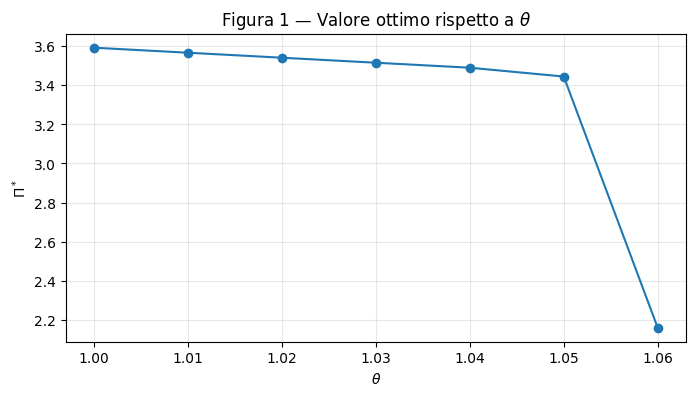

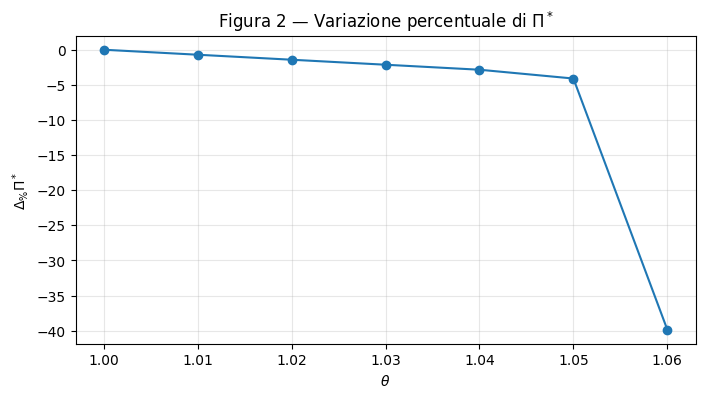

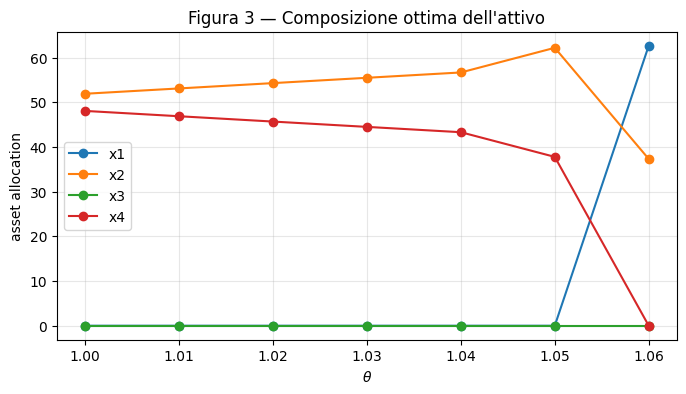

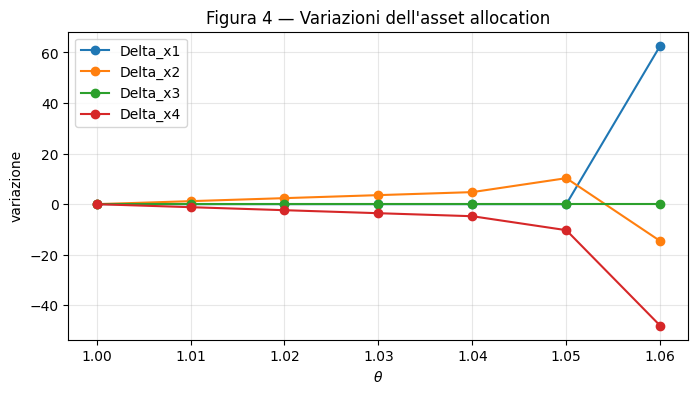

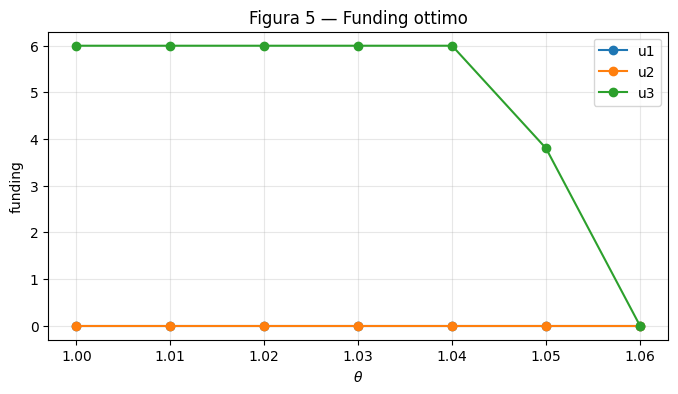

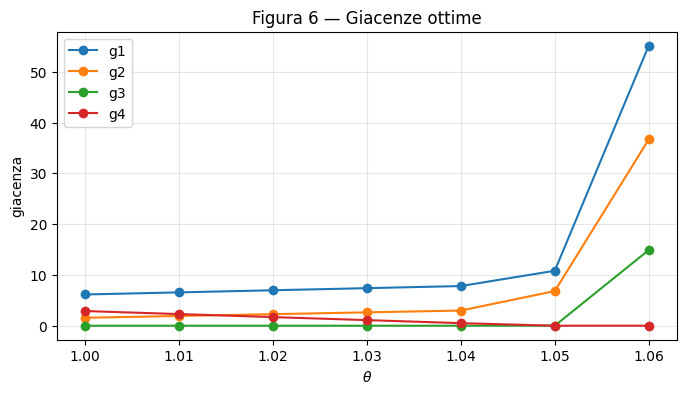

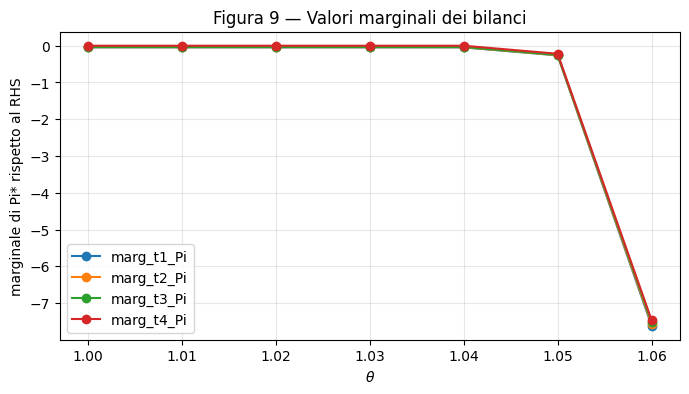

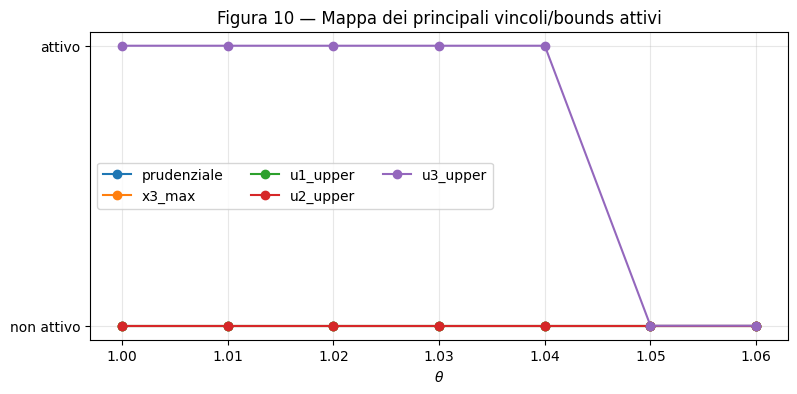

Tabella 9 — Raffinamento della frontiera


,theta,success
0,1.0600,True
1,1.0605,True
2,1.0610,True
3,1.0615,False
4,1.0620,False
5,1.0625,False
6,1.0630,False
7,1.0635,False
8,1.0640,False
9,1.0645,False


Intervallo raffinato contenente theta_crit: [1.061, 1.0615]


In [3]:
def solve_aula(theta=1.0,phi=1.0,psi=1.0):
    f1,Aeq,beq,Aub,bub,bnds,d=build_aula(theta,phi,psi)
    r=linprog(f1,A_ub=Aub,b_ub=bub,A_eq=Aeq,b_eq=beq,bounds=bnds,method="highs")
    out={"theta":theta,"phi":phi,"psi":psi,"success":bool(r.success),"status":int(r.status)}
    if not r.success:
        return out
    zz=r.x
    out.update({
        "Pi":-r.fun,"z":zz,"x":zz[:4],"g":zz[4:8],"u":zz[8:11],
        "eq_res":Aeq@zz-beq,"ub_slack":bub-Aub@zz,
        "eq_marg":r.eqlin.marginals,"ub_marg":r.ineqlin.marginals,
        "lower_marg":r.lower.marginals,"upper_marg":r.upper.marginals,"bounds":bnds
    })
    return out

b=solve_aula()
assert b["success"] and np.allclose(b["z"],z) and np.isclose(b["Pi"],Pi)

def aula_row(o,pname,pval):
    rr={pname:pval,"success":o["success"],"status":o["status"]}
    if not o["success"]: return rr
    rr["Pi"]=o["Pi"]; rr["Delta_Pi"]=o["Pi"]-Pi; rr["Delta_Pi_pct"]=100*(o["Pi"]/Pi-1)
    for j in range(4):
        rr[f"x{j+1}"]=o["x"][j]; rr[f"Delta_x{j+1}"]=o["x"][j]-x[j]
    for t in range(4):
        rr[f"g{t+1}"]=o["g"][t]
    for t in range(3):
        rr[f"u{t+1}"]=o["u"][t]
        cap=o["phi"]*u_bar[t]
        rr[f"rho_u{t+1}"]=o["u"][t]/cap if cap>0 else np.nan
    rr["prud_slack"]=o["ub_slack"][0]; rr["x3_slack"]=o["ub_slack"][1]
    rr["u1_upper_slack"]=o["bounds"][8][1]-o["u"][0]
    rr["u2_upper_slack"]=o["bounds"][9][1]-o["u"][1]
    rr["u3_upper_slack"]=o["bounds"][10][1]-o["u"][2]
    for t in range(4): rr[f"marg_t{t+1}_Pi"]=-o["eq_marg"][t+1]
    return rr

theta_grid=np.round(np.arange(1.00,1.101,0.01),2)
df_theta=pd.DataFrame([aula_row(solve_aula(theta=float(q)),"theta",q) for q in theta_grid])
print("Tabella 6 — Sensitività a theta")
display(df_theta)

v=df_theta[df_theta.success].copy()

# Figure 1-6
for fig_no,title,cols,ylabel in [
    (1,r"Valore ottimo rispetto a $\theta$",["Pi"],r"$\Pi^*$"),
    (2,r"Variazione percentuale di $\Pi^*$",["Delta_Pi_pct"],r"$\Delta_\%\Pi^*$"),
    (3,r"Composizione ottima dell'attivo",["x1","x2","x3","x4"],"asset allocation"),
    (4,r"Variazioni dell'asset allocation",["Delta_x1","Delta_x2","Delta_x3","Delta_x4"],"variazione"),
    (5,r"Funding ottimo",["u1","u2","u3"],"funding"),
    (6,r"Giacenze ottime",["g1","g2","g3","g4"],"giacenza"),
]:
    plt.figure(figsize=(8,4))
    for col in cols: plt.plot(v["theta"],v[col],marker="o",label=col)
    plt.xlabel(r"$\theta$"); plt.ylabel(ylabel); plt.title(f"Figura {fig_no} — {title}")
    if len(cols)>1: plt.legend()
    plt.grid(True,alpha=.3); plt.show()

# Figura 9
plt.figure(figsize=(8,4))
for col in ["marg_t1_Pi","marg_t2_Pi","marg_t3_Pi","marg_t4_Pi"]:
    plt.plot(v["theta"],v[col],marker="o",label=col)
plt.xlabel(r"$\theta$"); plt.ylabel("marginale di Pi* rispetto al RHS")
plt.title("Figura 9 — Valori marginali dei bilanci")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Figura 10
active=pd.DataFrame({
    "theta":v["theta"],
    "prudenziale":np.isclose(v["prud_slack"],0,atol=1e-7).astype(int),
    "x3_max":np.isclose(v["x3_slack"],0,atol=1e-7).astype(int),
    "u1_upper":np.isclose(v["u1_upper_slack"],0,atol=1e-7).astype(int),
    "u2_upper":np.isclose(v["u2_upper_slack"],0,atol=1e-7).astype(int),
    "u3_upper":np.isclose(v["u3_upper_slack"],0,atol=1e-7).astype(int),
})
plt.figure(figsize=(9,4))
for col in active.columns[1:]:
    plt.plot(active["theta"],active[col],marker="o",label=col)
plt.xlabel(r"$\theta$"); plt.yticks([0,1],["non attivo","attivo"])
plt.title("Figura 10 — Mappa dei principali vincoli/bounds attivi")
plt.legend(ncol=3); plt.grid(True,alpha=.3); plt.show()

feas=df_theta.loc[df_theta.success,"theta"].to_numpy()
infeas=df_theta.loc[~df_theta.success,"theta"].to_numpy()
last_feasible=feas.max()
first_infeasible=infeas[infeas>last_feasible].min()

ref_grid=np.round(np.arange(last_feasible,first_infeasible+0.0001,0.0005),4)
df_front=pd.DataFrame([{"theta":q,"success":solve_aula(theta=float(q))["success"]} for q in ref_grid])
last_ref=df_front.loc[df_front.success,"theta"].max()
first_ref=df_front.loc[(~df_front.success)&(df_front.theta>last_ref),"theta"].min()
print("Tabella 9 — Raffinamento della frontiera")
display(df_front)
print(f"Intervallo raffinato contenente theta_crit: [{last_ref}, {first_ref}]")

assert last_feasible < first_infeasible
assert last_ref < first_ref

# Tappa 4 — Sensitività a $\phi$ e a $\psi$
**Regime B**

**Obiettivo.** Analizzare separatamente capacità disponibile e costo del funding.

**Input.** `solve_aula` validata.

**Operazioni.**
- $\phi\in\{0.50,0.60,\ldots,1.50\}$ con $\theta=\psi=1$;
- $\psi\in\{0.50,0.75,\ldots,2.00\}$ con $\theta=\phi=1$.

**Output.** Tabelle 7–8 e Figure 7–8.

**Controlli.**
- $\phi$ modifica soltanto i bounds di funding;
- $\psi$ modifica sia i coefficienti di costo nell'obiettivo sia i rimborsi nei bilanci;
- uso esclusivo di soluzioni valide.

**Uso successivo.** Confronto complessivo dei driver e scenario analysis.

Tabella 7 — Sensitività a phi


,phi,success,status,Pi,Delta_Pi,Delta_Pi_pct,x1,Delta_x1,x2,Delta_x2,x3,Delta_x3,x4,Delta_x4,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,prud_slack,x3_slack,u1_upper_slack,u2_upper_slack,u3_upper_slack,marg_t1_Pi,marg_t2_Pi,marg_t3_Pi,marg_t4_Pi
0,0.5,True,0,3.565661,-0.026505,-0.737852,0.0,0.0,57.827312,5.907628,0.0,0.0,42.172688,-5.907628,9.696387,6.310332,0.0,3.011344,0.0,0.0,0.0,0.0,3.00000,1.000000,2.469639,30.0,5.0,4.0,0.00000,-0.045238,-0.040038,-0.033835,0.0
1,0.6,True,0,3.570962,-0.021204,-0.590282,0.0,0.0,56.645786,4.726103,0.0,0.0,43.354214,-4.726103,8.987472,5.361567,0.0,2.987107,0.0,0.0,0.0,0.0,3.60000,1.000000,2.398747,30.0,6.0,4.8,0.00000,-0.045238,-0.040038,-0.033835,0.0
2,0.7,True,0,3.576263,-0.015903,-0.442711,0.0,0.0,55.464261,3.544577,0.0,0.0,44.535739,-3.544577,8.278556,4.412801,0.0,2.962870,0.0,0.0,0.0,0.0,4.20000,1.000000,2.327856,30.0,7.0,5.6,0.00000,-0.045238,-0.040038,-0.033835,0.0
3,0.8,True,0,3.581564,-0.010602,-0.295141,0.0,0.0,54.282735,2.363051,0.0,0.0,45.717265,-2.363051,7.569641,3.464036,0.0,2.938632,0.0,0.0,0.0,0.0,4.80000,1.000000,2.256964,30.0,8.0,6.4,0.00000,-0.045238,-0.040038,-0.033835,0.0
4,0.9,True,0,3.586865,-0.005301,-0.147570,0.0,0.0,53.101209,1.181526,0.0,0.0,46.898791,-1.181526,6.860726,2.515271,0.0,2.914395,0.0,0.0,0.0,0.0,5.40000,1.000000,2.186073,30.0,9.0,7.2,0.00000,-0.045238,-0.040038,-0.033835,0.0
5,1.0,True,0,3.592166,0.000000,0.000000,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,1.566506,0.0,2.890158,0.0,0.0,0.0,0.0,6.00000,1.000000,2.115181,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.0
6,1.1,True,0,3.597467,0.005301,0.147570,0.0,0.0,50.738158,-1.181526,0.0,0.0,49.261842,1.181526,5.442895,0.617741,0.0,2.865921,0.0,0.0,0.0,0.0,6.60000,1.000000,2.044289,30.0,11.0,8.8,0.00000,-0.045238,-0.040038,-0.033835,0.0
7,1.2,True,0,3.600918,0.008752,0.243654,0.0,0.0,49.968867,-1.950817,0.0,0.0,50.031133,1.950817,4.981320,0.000000,0.0,2.850140,0.0,0.0,0.0,0.0,6.99066,0.970925,1.998132,30.0,12.0,9.6,0.20934,-0.041921,-0.036737,-0.025000,0.0
8,1.3,True,0,3.600918,0.008752,0.243654,0.0,0.0,49.968867,-1.950817,0.0,0.0,50.031133,1.950817,4.981320,0.000000,0.0,2.850140,0.0,0.0,0.0,0.0,6.99066,0.896238,1.998132,30.0,13.0,10.4,0.80934,-0.041921,-0.036737,-0.025000,0.0
9,1.4,True,0,3.600918,0.008752,0.243654,0.0,0.0,49.968867,-1.950817,0.0,0.0,50.031133,1.950817,4.981320,0.000000,0.0,2.850140,0.0,0.0,0.0,0.0,6.99066,0.832221,1.998132,30.0,14.0,11.2,1.40934,-0.041921,-0.036737,-0.025000,0.0


Tabella 8 — Sensitività a psi


,psi,success,status,Pi,Delta_Pi,Delta_Pi_pct,x1,Delta_x1,x2,Delta_x2,x3,Delta_x3,x4,Delta_x4,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,prud_slack,x3_slack,u1_upper_slack,u2_upper_slack,u3_upper_slack,marg_t1_Pi,marg_t2_Pi,marg_t3_Pi,marg_t4_Pi
0,0.50,True,0,3.667166,0.07500,2.087877,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,1.566506,0.0,2.965158,0.0,0.0,0.0,0.0,6.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
1,0.75,True,0,3.629666,0.03750,1.043938,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,1.566506,0.0,2.927658,0.0,0.0,0.0,0.0,6.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
2,1.00,True,0,3.592166,0.00000,0.000000,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,1.566506,0.0,2.890158,0.0,0.0,0.0,0.0,6.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
3,1.25,True,0,3.554666,-0.03750,-1.043938,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,1.566506,0.0,2.852658,0.0,0.0,0.0,0.0,6.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
4,1.50,True,0,3.539156,-0.05301,-1.475704,0.0,0.0,63.734940,11.815257,0.0,0.0,36.265060,-11.815257,13.240964,11.054157,0.0,3.132530,0.0,0.0,0.0,0.0,0.0,0.0,2.824096,30.0,10.0,8.0,6.0,-0.045238,-0.040038,-0.033835,0.0
5,1.75,True,0,3.539156,-0.05301,-1.475704,0.0,0.0,63.734940,11.815257,0.0,0.0,36.265060,-11.815257,13.240964,11.054157,0.0,3.132530,0.0,0.0,0.0,0.0,0.0,0.0,2.824096,30.0,10.0,8.0,6.0,-0.045238,-0.040038,-0.033835,0.0
6,2.00,True,0,3.539156,-0.05301,-1.475704,0.0,0.0,63.734940,11.815257,0.0,0.0,36.265060,-11.815257,13.240964,11.054157,0.0,3.132530,0.0,0.0,0.0,0.0,0.0,0.0,2.824096,30.0,10.0,8.0,6.0,-0.045238,-0.040038,-0.033835,0.0


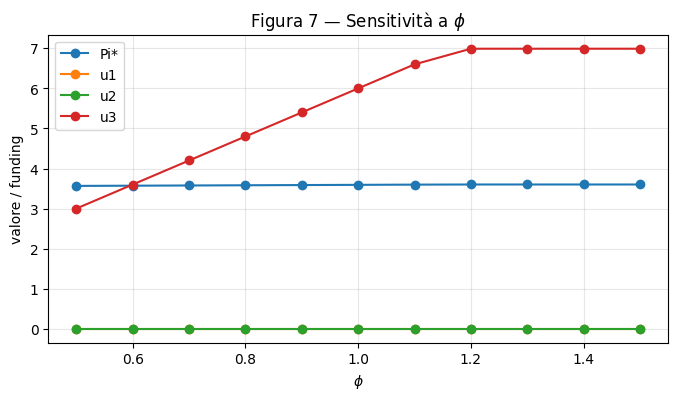

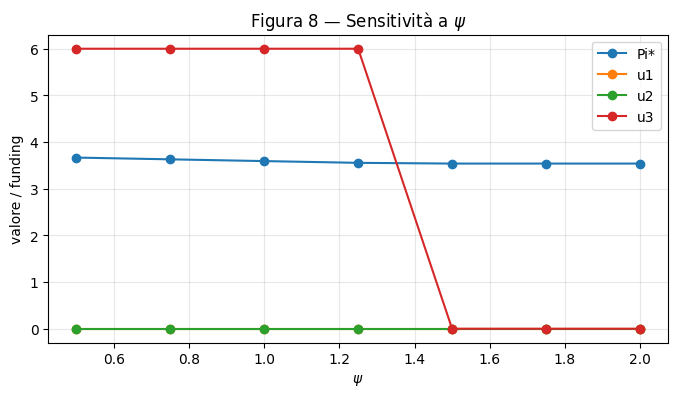

Controllo doppia azione di psi: OK


In [4]:
phi_grid=np.round(np.arange(0.50,1.501,0.10),2)
psi_grid=np.array([0.50,0.75,1.00,1.25,1.50,1.75,2.00])

df_phi=pd.DataFrame([aula_row(solve_aula(phi=float(q)),"phi",q) for q in phi_grid])
df_psi=pd.DataFrame([aula_row(solve_aula(psi=float(q)),"psi",q) for q in psi_grid])

print("Tabella 7 — Sensitività a phi")
display(df_phi)
print("Tabella 8 — Sensitività a psi")
display(df_psi)

vp=df_phi[df_phi.success]
plt.figure(figsize=(8,4))
plt.plot(vp["phi"],vp["Pi"],marker="o",label="Pi*")
for col in ["u1","u2","u3"]:
    plt.plot(vp["phi"],vp[col],marker="o",label=col)
plt.xlabel(r"$\phi$"); plt.ylabel("valore / funding")
plt.title(r"Figura 7 — Sensitività a $\phi$")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

vs=df_psi[df_psi.success]
plt.figure(figsize=(8,4))
plt.plot(vs["psi"],vs["Pi"],marker="o",label="Pi*")
for col in ["u1","u2","u3"]:
    plt.plot(vs["psi"],vs[col],marker="o",label=col)
plt.xlabel(r"$\psi$"); plt.ylabel("valore / funding")
plt.title(r"Figura 8 — Sensitività a $\psi$")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# controllo strutturale della doppia azione di psi
f_low,Aeq_low,_,_,_,_,_=build_aula(psi=0.5)
f_hi,Aeq_hi,_,_,_,_,_=build_aula(psi=2.0)
assert not np.allclose(f_low[8:11],f_hi[8:11])
assert not np.allclose(Aeq_low[:,8:11],Aeq_hi[:,8:11])
print("Controllo doppia azione di psi: OK")

# Tappa 5 — Confronto delle sensitività e scenario analysis
**Regime A/B**

**Obiettivo.** Mettere in relazione i tre driver senza confondere comparative statics e scenari.

**Input.** Risultati delle Tappe 3–4.

**Scenari**
- Standard: $(1.00,1.00,1.00)$;
- Mediamente critico: $(1.03,0.90,1.25)$;
- Critico: $(1.06,0.70,1.50)$.

**Output.** Sintesi delle tre sensitività, Tabella 10 e Figure 11–14.

**Controllo.** Standard uguale al benchmark, parametri esatti, stato solver verificato separatamente.

**Uso successivo.** Checklist conclusiva e interpretazione finale.

Sintesi sensitività


,driver,n_config,n_fattibili,Pi_min,Pi_max
0,theta,11,7,2.159921,3.592166
1,phi,11,11,3.565661,3.600918
2,psi,7,7,3.539156,3.667166


Tabella 10 — Confronto degli scenari


,scenario,theta,phi,psi,success,Pi,x1,x2,x3,x4,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,perdita_vs_Standard
0,Standard,1.00,1.0,1.00,True,3.592166,0.000000,51.919684,0.0,48.080316,6.151810,1.566506,0.00000,2.890158,0.0,0.0,0.0,0.0,6.0,1.0,0.000000
1,Mediamente critico,1.03,0.9,1.25,True,3.476367,0.000000,56.675969,0.0,43.324031,8.105581,3.581303,0.00000,1.093266,0.0,0.0,0.0,0.0,5.4,1.0,0.115799
2,Critico,1.06,0.7,1.50,True,2.159921,62.671906,37.328094,0.0,0.000000,55.135167,36.675676,14.89573,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.432245


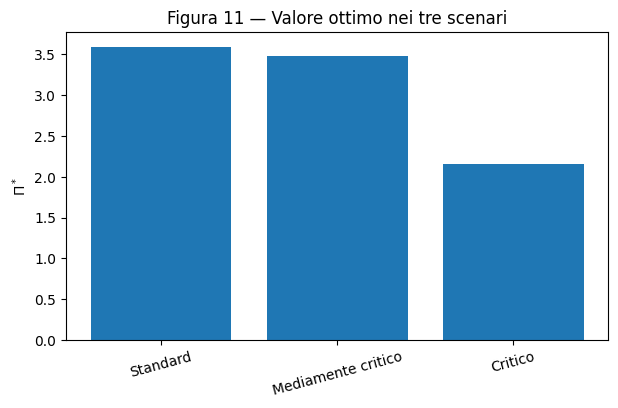

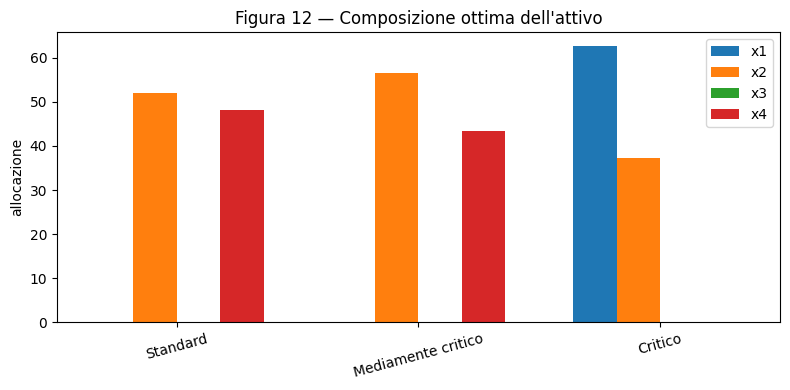

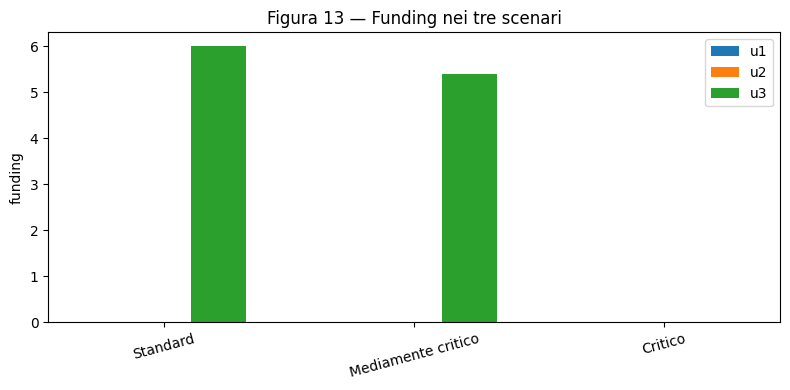

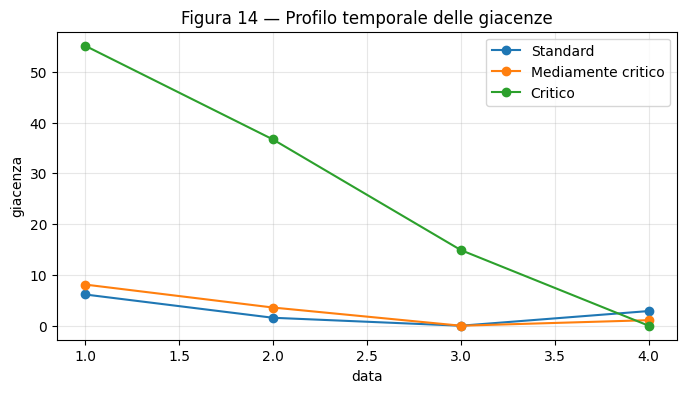

Scenario Standard = benchmark: OK


In [5]:
summary=pd.DataFrame([
    ["theta",len(df_theta),int(df_theta.success.sum()),df_theta.loc[df_theta.success,"Pi"].min(),df_theta.loc[df_theta.success,"Pi"].max()],
    ["phi",len(df_phi),int(df_phi.success.sum()),df_phi.loc[df_phi.success,"Pi"].min(),df_phi.loc[df_phi.success,"Pi"].max()],
    ["psi",len(df_psi),int(df_psi.success.sum()),df_psi.loc[df_psi.success,"Pi"].min(),df_psi.loc[df_psi.success,"Pi"].max()],
],columns=["driver","n_config","n_fattibili","Pi_min","Pi_max"])
print("Sintesi sensitività")
display(summary)

scenari={
    "Standard":(1.00,1.00,1.00),
    "Mediamente critico":(1.03,0.90,1.25),
    "Critico":(1.06,0.70,1.50)
}
rows=[]
for nome,(th,ph,ps) in scenari.items():
    o=solve_aula(th,ph,ps)
    row={"scenario":nome,"theta":th,"phi":ph,"psi":ps,"success":o["success"]}
    if o["success"]:
        row["Pi"]=o["Pi"]
        for j in range(4): row[f"x{j+1}"]=o["x"][j]
        for t in range(4): row[f"g{t+1}"]=o["g"][t]
        for t in range(3):
            row[f"u{t+1}"]=o["u"][t]
            row[f"rho_u{t+1}"]=o["u"][t]/(ph*u_bar[t])
    rows.append(row)
df_scen=pd.DataFrame(rows)
Pi_std=df_scen.loc[df_scen.scenario=="Standard","Pi"].iloc[0]
df_scen["perdita_vs_Standard"]=np.where(df_scen.success,Pi_std-df_scen["Pi"],np.nan)
print("Tabella 10 — Confronto degli scenari")
display(df_scen)

valid=df_scen[df_scen.success]

plt.figure(figsize=(7,4))
plt.bar(valid["scenario"],valid["Pi"]); plt.ylabel(r"$\Pi^*$")
plt.title("Figura 11 — Valore ottimo nei tre scenari"); plt.xticks(rotation=15); plt.show()

plt.figure(figsize=(8,4))
pos=np.arange(len(valid))
w=0.18
for j,col in enumerate(["x1","x2","x3","x4"]):
    plt.bar(pos+(j-1.5)*w,valid[col],width=w,label=col)
plt.xticks(pos,valid["scenario"],rotation=15); plt.ylabel("allocazione")
plt.title("Figura 12 — Composizione ottima dell'attivo"); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
w=0.22
for j,col in enumerate(["u1","u2","u3"]):
    plt.bar(pos+(j-1)*w,valid[col],width=w,label=col)
plt.xticks(pos,valid["scenario"],rotation=15); plt.ylabel("funding")
plt.title("Figura 13 — Funding nei tre scenari"); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
for _,r in valid.iterrows():
    plt.plot([1,2,3,4],[r[f"g{i}"] for i in range(1,5)],marker="o",label=r["scenario"])
plt.xlabel("data"); plt.ylabel("giacenza"); plt.title("Figura 14 — Profilo temporale delle giacenze")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

assert np.isclose(Pi_std,Pi)
print("Scenario Standard = benchmark: OK")

# Tappa 6 — Controlli conclusivi e predisposizione dell'interpretazione
**Regime A**

**Obiettivo.** Verificare coerenza globale e delimitare il significato dei risultati.

**Controlli conclusivi.**
- forma solver coerente con la Scheda Caso;
- benchmark valido;
- marginale verificato localmente;
- funzione parametrica che replica il benchmark;
- griglie complete e un solo parametro variato;
- frontiera costruita da un bracket feasible/infeasible;
- doppia azione di $\psi$ verificata;
- scenari assegnati esattamente;
- output costruiti solo da soluzioni valide;
- notebook rieseguibile dall'inizio.

**Limiti interpretativi.**
Il modello è deterministico e stilizzato; $\theta_{\mathrm{crit}}$ è una frontiera del modello, non una stima empirica della soglia storica di deflusso di SVB.

**Uso successivo.** Gli output validati costituiscono la base per il commento finanziario autonomo dello studente.

In [6]:
checks={
    "benchmark_success":bool(res.success),
    "eq_residuals_ok":bool(np.max(np.abs(A_eq@z-b_eq))<1e-7),
    "inequalities_ok":bool(np.all(b_ub-A_ub@z>=-1e-7)),
    "nonnegative_ok":bool(np.min(z)>=-1e-7),
    "u3_upper_active":bool(abs(u[2]-u_bar[2])<1e-7),
    "marginal_check_ok":bool(abs(num-theo)<1e-6),
    "parametric_benchmark_ok":bool(np.allclose(solve_aula()["z"],z)),
    "theta_grid_complete":bool(len(df_theta)==11),
    "phi_grid_complete":bool(len(df_phi)==11),
    "psi_grid_complete":bool(len(df_psi)==7),
    "frontier_bracket_ok":bool(last_feasible<first_infeasible and last_ref<first_ref),
    "scenarios_complete":bool(len(df_scen)==3),
    "standard_equals_benchmark":bool(np.isclose(Pi_std,Pi))
}
tab_checks=pd.DataFrame({"controllo":list(checks.keys()),"esito":list(checks.values())})
display(tab_checks)
assert all(checks.values())
print("Tutti i controlli conclusivi: OK")

,controllo,esito
0,benchmark_success,True
1,eq_residuals_ok,True
2,inequalities_ok,True
3,nonnegative_ok,True
4,u3_upper_active,True
5,marginal_check_ok,True
6,parametric_benchmark_ok,True
7,theta_grid_complete,True
8,phi_grid_complete,True
9,psi_grid_complete,True


Tutti i controlli conclusivi: OK


# Interpretazione finanziaria finale — spazio dello studente

Da completare autonomamente sulla base degli output già validati.

Il commento finale deve discutere almeno:
1. composizione del piano benchmark;
2. ruolo di funding, giacenze, vincoli e bounds attivi;
3. differenze economiche fra $\theta$, $\phi$ e $\psi$;
4. significato della frontiera di fattibilità;
5. distinzione tra sensitività univariate e scenari;
6. limiti del modello e distinzione rispetto ai fatti storici di Silicon Valley Bank.